# Checkpoint samples

Sample each diffusion model on its own from pure noise and look at the result. Use it on the authors' checkpoints as a reference, and on your own `ema_*.pt` files during training.

- **64×64 defect model**: one row per defect class
- **256×256 defect-free model**: a grid of clean board crops
- No CRG guidance here, so the pictures show only what each network has learned.

Run in the `crg-defect` kernel. Change the settings cell, then *Run All*.

In [4]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

# 找到 Graduate_Design/：从当前目录向上找含 third_party/CRG-DefectDiffuser 的目录
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "third_party" / "CRG-DefectDiffuser").is_dir())
REPO = ROOT / "third_party" / "CRG-DefectDiffuser"     # 模型代码与配置（guided_diffusion/、confs/、data/pcb.json）
CKPT_DIR = ROOT / "checkpoint"                           # checkpoint 存放位置
OUT_DIR = ROOT / "results" / "checkpoint_samples"
sys.path.insert(0, str(REPO))

from guided_diffusion.gaussian_diffusion import get_named_beta_schedule
from guided_diffusion.script_util import create_model, model_defaults, select_args

device = "cuda" if torch.cuda.is_available() else "cpu"
print("ROOT  ", ROOT)
print("device", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

ROOT   /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design
device cuda NVIDIA GeForce RTX 4090


## Settings

In [5]:
CKPT_64 = CKPT_DIR / "checkpoint-64-defect.pt"          # 换成自己的 ema_0.9999_XXXXXX.pt
CKPT_256 = CKPT_DIR / "checkpoint-256-defect-free.pt"
CONF = REPO / "confs" / "pcb_gen.yml"                   # 网络结构；自己改了结构就换成对应配置
CLASSES = REPO / "data" / "pcb.json"

N_PER_CLASS = 8      # 64 模型每类样本数
N_256 = 8            # 256 模型样本数
STEPS = 100          # DDIM 步数，50 更快
SEED = 0
SAVE = True          # 同时把图保存到 results/checkpoint_samples/

## Helpers

In [6]:
conf = yaml.safe_load(open(CONF))
classes = json.load(open(CLASSES))                       # 名称 -> id
betas = get_named_beta_schedule(conf["noise_schedule"], conf["diffusion_steps"], use_scale=True)
alphas_cumprod = torch.tensor(np.cumprod(1.0 - betas), dtype=torch.float32, device=device)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def load_model(which, ckpt):
    """which = "64" 或 "256"；按配置建网络并严格加载权重"""
    if which == "64":
        model = create_model(**conf["crop"], num_classes=len(classes))
    else:
        model = create_model(**select_args(conf, model_defaults().keys()))
    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
    return model.to(device).eval()


@torch.no_grad()
def ddim_sample(model, shape, steps=STEPS, y=None, keep_every=None):
    """确定性 DDIM（σ=0）。返回 [0,1] 图像 (N,H,W,3)；keep_every 不为空时同时返回中间的 x̂0 预测"""
    x = torch.randn(shape, device=device)
    ts = np.linspace(len(alphas_cumprod) - 1, 0, steps).round().astype(int)
    history = []
    for i, t in enumerate(ts):
        eps = model(x, torch.full((shape[0],), int(t), device=device), y)[:, :3]   # 前 3 通道是 ε
        a_t = alphas_cumprod[t]
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        if keep_every and (i % keep_every == 0 or i == len(ts) - 1):
            history.append((int(t), to_img(x0)))
        if i == len(ts) - 1:
            x = x0
            break
        a_prev = alphas_cumprod[ts[i + 1]]
        x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps
    return (to_img(x), history) if keep_every else to_img(x)


def to_img(x):
    return ((x + 1) / 2).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()


def show_grid(rows, row_labels=None, col_labels=None, title="", cell=1.3, save_as=None):
    """rows: list[list[image]]，每个内层列表是一行"""
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(cell * nc + 1.6, cell * nr + 0.7), squeeze=False)
    for r in range(nr):
        for c in range(nc):
            ax = axes[r, c]
            ax.set_xticks([]), ax.set_yticks([])
            if c < len(rows[r]):
                ax.imshow(rows[r][c], interpolation="nearest")
            else:
                ax.axis("off")
        if row_labels:
            axes[r, 0].set_ylabel(row_labels[r], rotation=0, ha="right", va="center", fontsize=10)
    if col_labels:
        for c, lab in enumerate(col_labels):
            axes[0, c].set_title(lab, fontsize=9)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    if SAVE and save_as:
        fig.savefig(OUT_DIR / save_as, dpi=150)
        print("saved", OUT_DIR / save_as)
    plt.show()


def free(model):
    del model
    if device == "cuda":
        torch.cuda.empty_cache()

## Noise schedule

How much of the clean image is left at each timestep: $\sqrt{\bar\alpha_t}$ for the signal, $\sqrt{1-\bar\alpha_t}$ for the noise. The dots are the timesteps the DDIM sampler below actually visits.

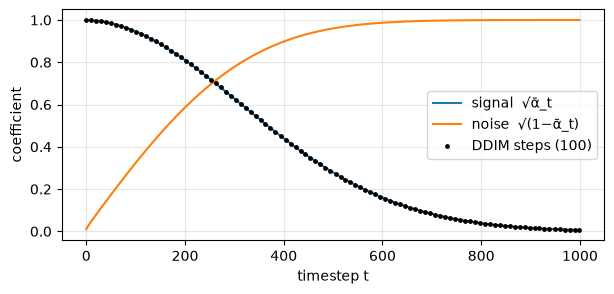

In [7]:
ab = alphas_cumprod.cpu().numpy()
ts = np.linspace(len(ab) - 1, 0, STEPS).round().astype(int)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.sqrt(ab), label="signal  √ᾱ_t")
ax.plot(np.sqrt(1 - ab), label="noise  √(1−ᾱ_t)")
ax.scatter(ts, np.sqrt(ab[ts]), s=6, color="k", zorder=3, label=f"DDIM steps ({STEPS})")
ax.set_xlabel("timestep t"), ax.set_ylabel("coefficient"), ax.legend(), ax.grid(alpha=0.3)
plt.show()

## 64×64 defect model — samples per class

create model:image_size:64, attention_ds:[4, 8], use_fp16:False!
saved /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/results/checkpoint_samples/checkpoint-64-defect_64.png


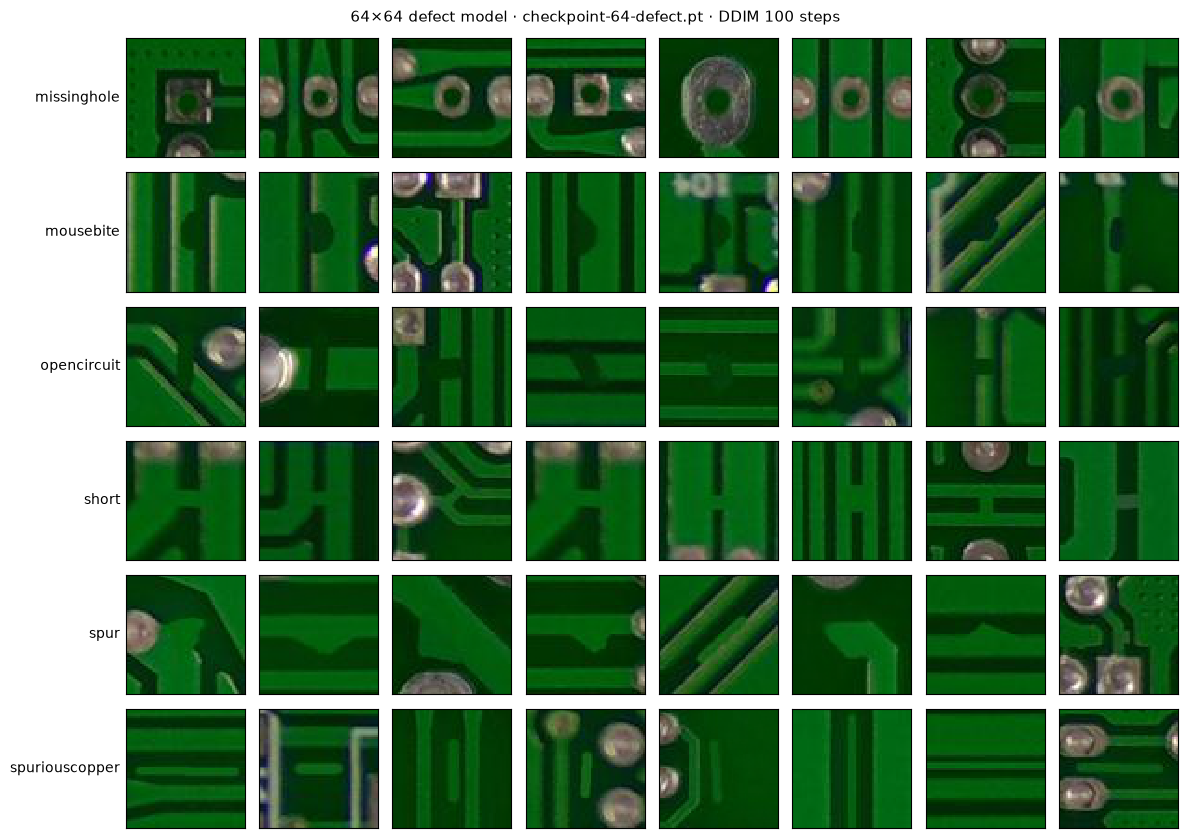

In [8]:
torch.manual_seed(SEED)
model = load_model("64", CKPT_64)
rows = []
for name, cid in classes.items():
    y = torch.full((N_PER_CLASS,), cid, device=device)
    rows.append(list(ddim_sample(model, (N_PER_CLASS, 3, 64, 64), y=y)))
show_grid(rows, row_labels=list(classes),
          title=f"64×64 defect model · {CKPT_64.name} · DDIM {STEPS} steps",
          save_as=f"{CKPT_64.stem}_64.png")

## How a defect forms during sampling

The model's guess of the clean patch $\hat x_0$ at several timesteps, from pure noise (left) to the final sample (right). Near t=999 the guess is a blur. The layout of pads and traces, including the defect, settles in the middle steps (about t=500 to 350); after that only fine detail and sharpness change.

saved /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/results/checkpoint_samples/checkpoint-64-defect_64_process_short.png


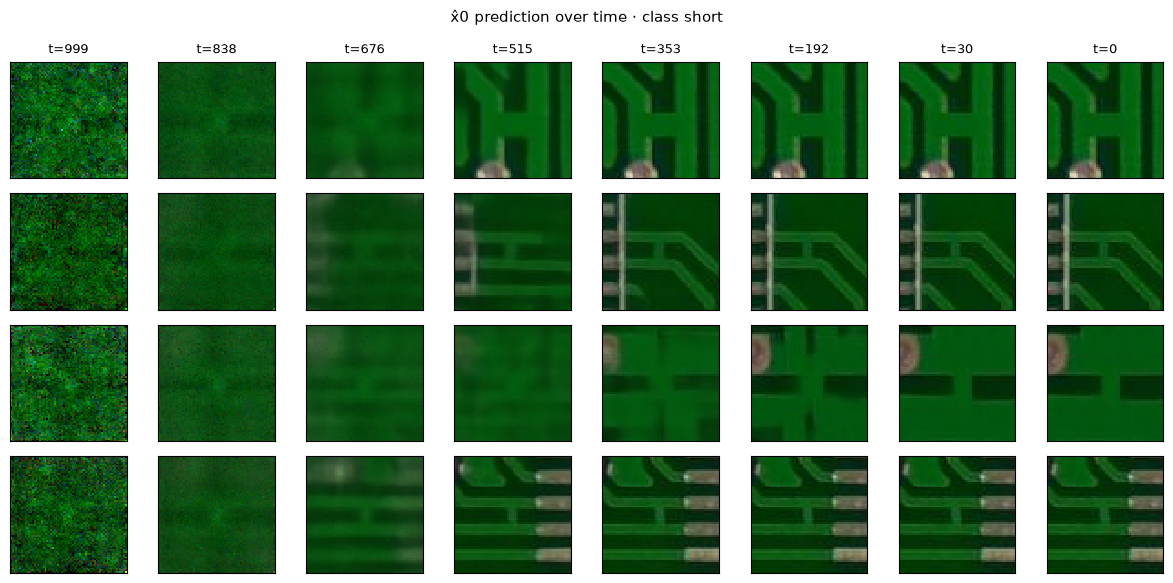

In [9]:
SHOW_CLASS = "short"     # missinghole / mousebite / opencircuit / short / spur / spuriouscopper
N_SHOW = 4

torch.manual_seed(SEED)
y = torch.full((N_SHOW,), classes[SHOW_CLASS], device=device)
_, history = ddim_sample(model, (N_SHOW, 3, 64, 64), y=y, keep_every=max(1, STEPS // 6))
rows = [[img[k] for _, img in history] for k in range(N_SHOW)]
show_grid(rows, col_labels=[f"t={t}" for t, _ in history],
          title=f"x̂0 prediction over time · class {SHOW_CLASS}",
          save_as=f"{CKPT_64.stem}_64_process_{SHOW_CLASS}.png")
free(model)

## 256×256 defect-free model

create model:image_size:256, attention_ds:[16, 32], use_fp16:False!
saved /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/results/checkpoint_samples/checkpoint-256-defect-free_256.png


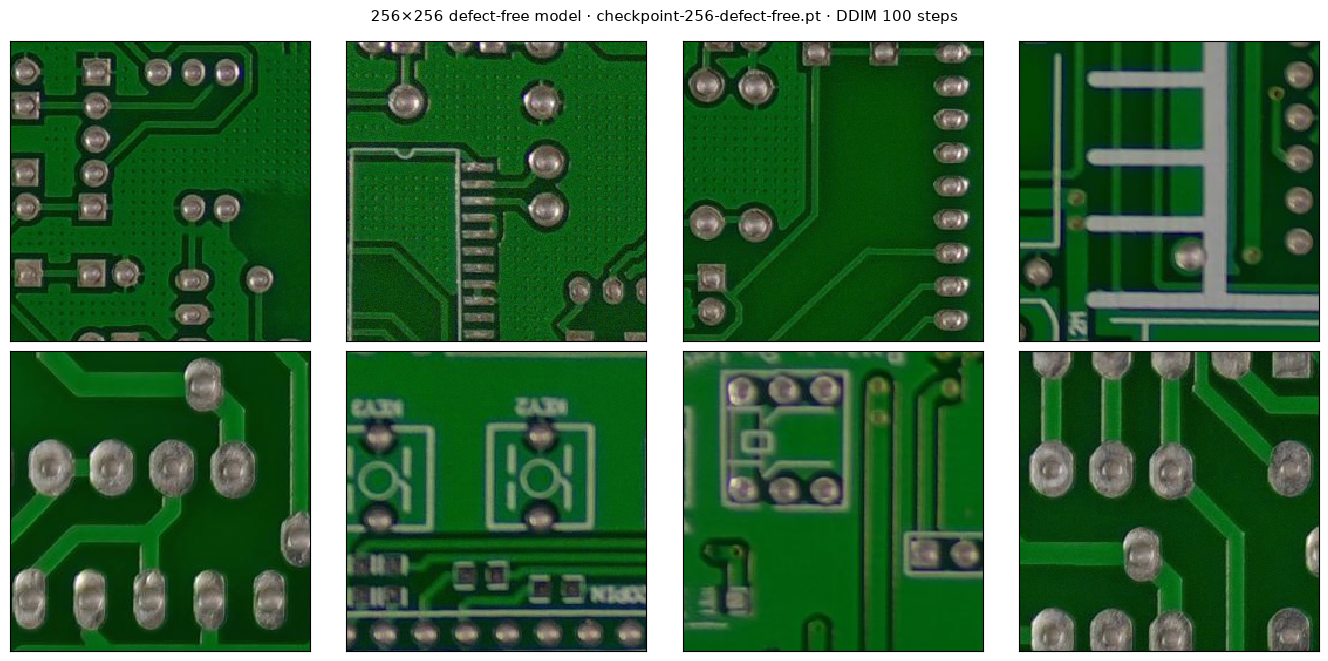

In [10]:
torch.manual_seed(SEED)
model = load_model("256", CKPT_256)
imgs = []
for start in range(0, N_256, 4):                         # 每批 4 张，控制显存
    imgs.extend(ddim_sample(model, (min(4, N_256 - start), 3, 256, 256)))
show_grid([imgs[i:i + 4] for i in range(0, len(imgs), 4)], cell=3,
          title=f"256×256 defect-free model · {CKPT_256.name} · DDIM {STEPS} steps",
          save_as=f"{CKPT_256.stem}_256.png")
free(model)

## Compare checkpoints (training progress)

List several 64-model checkpoints, for example your `ema_*.pt` files at different steps. Every row uses the **same starting noise**, so the only difference between rows is the training step. With only the authors' checkpoint there is one row.

create model:image_size:64, attention_ds:[4, 8], use_fp16:False!
saved /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/results/checkpoint_samples/compare_checkpoints_64.png


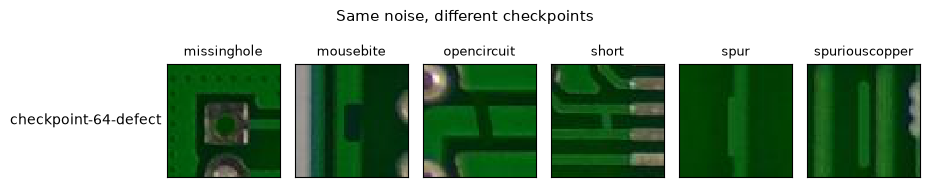

: 

In [ ]:
CKPTS = [CKPT_64]
# 训练后例如：CKPTS = sorted((ROOT / "runs" / "defect_64").glob("ema_0.9999_*.pt"))

y = torch.tensor(list(classes.values()), device=device)   # 每个类别一张
rows = []
for ck in CKPTS:
    m = load_model("64", ck)
    torch.manual_seed(SEED)                              # 每个 checkpoint 用同一份初始噪声
    rows.append(list(ddim_sample(m, (len(classes), 3, 64, 64), y=y)))
    free(m)
show_grid(rows, row_labels=[Path(c).stem for c in CKPTS], col_labels=list(classes),
          title="Same noise, different checkpoints", save_as="compare_checkpoints_64.png")